# Home Credit Scorecard Model
### Notebook 04 — Validation recap, feature selection, imbalance handling, modelling and evaluation (Steps 6–9)

Run order: `01` → `02` → `03` → **this notebook**. It uses the modelling dataset and validation split saved earlier and
starts a fresh Python process. Full run: about one hour on a single CPU, and faster on multi-core machines because the
gradient-boosting model uses all cores.

**Resumable.** Each cross-validation result is cached in `data/processed/cv_cache/` under a fingerprint of the data, the full
pipeline configuration and the fold settings. If the run is interrupted, re-running the notebook reuses finished work, and
any change to data or code is recomputed automatically. Delete that folder to force a run entirely from scratch.

Setting the environment variable `HC_QUICK=1` runs a 15% **smoke test** (to check the code in a few minutes). Its outputs
are **not valid results**. In that mode no models or predictions are saved, but the report tables and figures in
`reports/` are overwritten, so always finish with a full run.

In [1]:
import ctypes
import gc
import json
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import roc_auc_score

SEED = 42
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def find_project_root(start: Path) -> Path:
    """Project root = the folder containing src/build_dataset.py, searched upward from the notebook folder.
    Override with the HC_PROJECT_ROOT environment variable."""
    if os.environ.get("HC_PROJECT_ROOT"):
        return Path(os.environ["HC_PROJECT_ROOT"]).resolve()
    for folder in [start, *start.parents]:
        if (folder / "src" / "build_dataset.py").exists():
            return folder
    raise FileNotFoundError(
        f"Project root not found searching upward from {start}.\n"
        "Expected folder layout:\n"
        "  home-credit-scorecard-model/\n"
        "    notebooks/02_dataset_preprocessing.ipynb   <- this notebook\n"
        "    src/__init__.py, src/build_dataset.py, src/preprocessing.py\n"
        "    data/raw/   (the provided CSV files)\n"
        "Fix: unzip the complete project folder and open the notebook from its notebooks/ folder, "
        "or set HC_PROJECT_ROOT to the folder that contains src/.")


ROOT = find_project_root(Path.cwd().resolve())
for f in ["__init__.py", "build_dataset.py", "preprocessing.py"]:
    assert (ROOT / "src" / f).exists(), f"Missing {ROOT / 'src' / f} - copy the complete src/ folder"

# Package checks (clear messages instead of obscure errors later)
import re
_skl = tuple(int(x) for x in re.findall(r"\d+", sklearn.__version__)[:2])
assert _skl >= (1, 7), (
    f"scikit-learn {sklearn.__version__} found; 1.7 or newer is required. "
    "Run: pip install -U scikit-learn  (or: conda install -c conda-forge scikit-learn>=1.7)")
try:
    import pyarrow  # noqa: F401  (needed for the .parquet dataset files)
except ImportError as e:
    raise ImportError("pyarrow is required. Run: pip install pyarrow  (or: conda install -c conda-forge pyarrow)") from e

DATA_CANDIDATES = [os.environ.get("HC_DATA_DIR"), ROOT / "data" / "raw", Path("/mnt/user-data/uploads")]
DATA_DIR = next((Path(c) for c in DATA_CANDIDATES if c and (Path(c) / "application_train.csv").exists()), None)
assert DATA_DIR is not None, "application_train.csv not found - set HC_DATA_DIR or place files in data/raw"
REPORTS, FIG, PROCESSED = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "data" / "processed"
assert (PROCESSED / "split_assignment.csv").exists(), "Run notebook 01 first: it creates the validation split"


def release_memory():
    # Free Python objects and hand unused heap memory back to the operating system
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError:
        pass


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print("Project root:", ROOT)
print("DATA_DIR:", DATA_DIR)
import warnings
for f in ["abt_train.parquet", "abt_test.parquet", "data_dictionary.csv"]:
    assert (PROCESSED / f).exists(), f"{f} not found - run notebook 02 first (it builds the modelling dataset)"

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0
Project root: /mnt/user-data/outputs/home-credit-scorecard-model
DATA_DIR: /mnt/user-data/uploads


In [2]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import joblib
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.model_selection import ParameterSampler
from src.evaluation import (calibration_table, cv_isotonic, expected_calibration_error, f1_optimal_threshold,
                            ranking_metrics, threshold_metrics)
from src.modeling import SEED, cross_validate, feature_set, make_hgb, make_lr, paired_summary, restrict
from src.preprocessing import DRIFT_RISK, decide_columns, predefined_folds

warnings.filterwarnings("ignore", message=".*Bins whose width are too small.*")
QUICK = os.environ.get("HC_QUICK") == "1"     # smoke-test mode (15% of rows, small searches); never used for reported results
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

abt = pd.read_parquet(PROCESSED / "abt_train.parquet")
if QUICK:
    abt = abt.groupby("fold", group_keys=False).sample(frac=0.15, random_state=SEED)
split_overview = abt.assign(partition=np.where(abt.fold == -1, "holdout (locked)", "dev fold " + abt.fold.astype(str)))
dev = abt[abt.fold >= 0].reset_index(drop=True)
del abt                                         # the holdout is reloaded only in Section 17.6
release_memory()
y_dev = dev.TARGET.to_numpy()
folds = predefined_folds(dev.fold)
X_dev = dev.drop(columns=["TARGET", "fold"])    # model inputs never contain the target (pipelines select features by name)

# Resumable execution: results are cached under a fingerprint of the data, the full pipeline configuration and the
# fold settings, so a restarted run reuses finished work and any change to data or code recomputes automatically.
CACHE = PROCESSED / "cv_cache"
CACHE.mkdir(exist_ok=True)
DATA_FP = joblib.hash((X_dev, y_dev, dev.fold.to_numpy()))
print("Data fingerprint:", DATA_FP[:12], "| cache:", CACHE)
print(f"Mode: {'QUICK SMOKE TEST - results not valid' if QUICK else 'full data'} | development rows: {len(dev):,}")

Data fingerprint: 15b1aa9f86f7 | cache: /mnt/user-data/outputs/home-credit-scorecard-model/data/processed/cv_cache
Mode: full data | development rows: 246,008


## 14. Step 6 — Train, validation and test strategy (recap)

The validation design was fixed in notebook 01 (Section 8), before any modelling, and is reused unchanged:

| Partition | Rows | Used for |
|---|---|---|
| Development folds 0–4 | 80% of `application_train` | Feature selection, imbalance handling, tuning and model comparison, always on the same 5 stratified folds |
| Locked holdout | 20% of `application_train` | One final, unbiased evaluation of the selected model (Section 17.6) |
| Scoring set (`application_test`) | 48,744 unlabelled loans | Final predictions and stability checks only; never used to fit or choose anything |

**Leakage controls.**
* Every learned transformation sits inside a pipeline fitted on the training part of each fold (tested in notebook 02).
* Resampling, where tested, touches training indices only.
* The holdout is not loaded until Section 17.6.

**Limitations.**
* **No calendar dates exist**, so an out-of-time validation is impossible. Random folds are likely to overstate performance on future
  applicants.
* **`SK_ID_CURR` identifies a loan, not a person**, so repeat clients cannot be kept together within a fold.
* **The scoring set differs from train** (product mix, missingness, `APP_CREDIT_TERM`). Section 17.4 measures how sensitive the models
  are to the unstable features.

All random seeds are fixed (`SEED = 42`).

In [3]:
display(split_overview.groupby("partition").agg(rows=("TARGET", "size"), positives=("TARGET", "sum"),
                                                target_pct=("TARGET", lambda s: round(100 * s.mean(), 3))))
del split_overview
release_memory()

,rows,positives,target_pct
partition,,,
dev fold 0,49202,3972.0,8.073
dev fold 1,49202,3972.0,8.073
dev fold 2,49202,3972.0,8.073
dev fold 3,49201,3972.0,8.073
dev fold 4,49201,3972.0,8.073
holdout (locked),61503,4965.0,8.073


## 15. Step 7 — Feature selection and imbalance handling

**Starting point.** The ALL feature set from Step 5: the application form plus every history table, after Step 4's column
rules, with drift-risk features and `CODE_GENDER` excluded. Two reference models are cross-validated on it:
* **Logistic Regression**: Step 4 preprocessing variant D, C = 1, no class weighting;
* **Gradient boosting**: `HistGradientBoostingClassifier` with library defaults.

**Decision rule, fixed before seeing the results.** A feature-set reduction is adopted if it costs **at most 0.0005 mean
ROC-AUC for both models**. A smaller model that is just as accurate is cheaper to run, monitor and explain.

In [4]:
RESULTS, OOF = [], {}

def run(label, make_pipe, fold_ids=None, undersample_ratio=None):
    """Cross-validate once per label and keep per-fold metrics and out-of-fold predictions (cached)."""
    t = time.time()
    key = joblib.hash((DATA_FP, make_pipe(), tuple(fold_ids or range(len(folds))), undersample_ratio))
    path = CACHE / f"cv_{key}.joblib"
    if path.exists():
        res, oof = joblib.load(path)
        res = res.assign(label=label)
        status = "cached"
    else:
        res, oof = cross_validate(make_pipe, X_dev, y_dev, folds, label, fold_ids, undersample_ratio)
        joblib.dump((res, oof), path)
        status = f"{time.time() - t:4.0f}s"
    RESULTS.append(res)
    OOF[label] = oof
    print(f"{label:42s} ROC-AUC {res.roc_auc.mean():.4f} over {len(res)} folds  ({status})", flush=True)
    return res

def results():
    return pd.concat(RESULTS, ignore_index=True)

t0 = time.time()
cols_all = decide_columns(dev)
ALL = feature_set(cols_all)
print(f"Column rules applied ({time.time() - t0:.0f}s): {len(ALL)} usable features "
      f"({len(cols_all['lr_continuous']) + len(cols_all['binary']) + len(cols_all['categorical'])} after the LR-only redundancy rule)")
run("LR | ALL", lambda: make_lr(cols_all))
run("HGB | ALL", lambda: make_hgb(cols_all))

Column rules applied (50s): 181 usable features (164 after the LR-only redundancy rule)


LR | ALL                                   ROC-AUC 0.7779 over 5 folds  (cached)


HGB | ALL                                  ROC-AUC 0.7795 over 5 folds  (cached)


,roc_auc,gini,pr_auc,ks,brier,log_loss,label,fold,fit_seconds,predict_seconds_per_1k,n_iter,train_rows
0,0.776163,0.552327,0.261992,0.423027,0.066788,0.240924,HGB | ALL,0,25.654051,0.022900,100,196806
1,0.778269,0.556537,0.260123,0.420577,0.066897,0.240792,HGB | ALL,1,26.189772,0.019045,94,196806
2,0.779100,0.558200,0.274589,0.423792,0.066335,0.239486,HGB | ALL,2,25.859333,0.026063,100,196806
3,0.783460,0.566921,0.272871,0.432244,0.066285,0.238662,HGB | ALL,3,25.922749,0.029992,100,196807
4,0.780531,0.561062,0.264538,0.420922,0.066635,0.239885,HGB | ALL,4,26.125267,0.024798,100,196807


### 15.1 Do the external-score summaries add anything beyond the raw scores?
`APP_EXT_MEAN`, `_MIN`, `_MAX` and `_STD` are functions of `EXT_SOURCE_1–3`. Step 4 measured VIFs of 20–82 for them, and Step 5
gave them the highest IV. If the models can extract the same information from the three raw scores, the summaries add
collinearity without adding signal.

In [5]:
EXT_SUMMARY = {"APP_EXT_MEAN", "APP_EXT_MIN", "APP_EXT_MAX", "APP_EXT_STD"}
cols_noext = restrict(cols_all, ALL - EXT_SUMMARY)
run("LR | ALL - EXT summaries", lambda: make_lr(cols_noext))
run("HGB | ALL - EXT summaries", lambda: make_hgb(cols_noext))
r = results()
s = pd.concat([paired_summary(r, "LR | ALL", ["LR | ALL", "LR | ALL - EXT summaries"]),
               paired_summary(r, "HGB | ALL", ["HGB | ALL", "HGB | ALL - EXT summaries"])])
display(s[["roc_auc", "roc_auc_std", "pr_auc", "auc_diff_vs_ref", "folds_better_than_ref"]].round(4))
drop_ext = bool((s.loc[["LR | ALL - EXT summaries", "HGB | ALL - EXT summaries"], "auc_diff_vs_ref"] >= -0.0005).all())
print("Decision rule (cost <= 0.0005 ROC-AUC for both models):", "REMOVE the summaries" if drop_ext else "KEEP the summaries")
CURRENT = ALL - EXT_SUMMARY if drop_ext else ALL
CURRENT_LABEL = "ALL - EXT summaries" if drop_ext else "ALL"

LR | ALL - EXT summaries                   ROC-AUC 0.7777 over 5 folds  (cached)


HGB | ALL - EXT summaries                  ROC-AUC 0.7800 over 5 folds  (cached)


,roc_auc,roc_auc_std,pr_auc,auc_diff_vs_ref,folds_better_than_ref
label,,,,,
LR | ALL,0.7779,0.0028,0.2654,0.0000,0
LR | ALL - EXT summaries,0.7777,0.0028,0.2646,-0.0003,1
HGB | ALL,0.7795,0.0027,0.2668,0.0000,0
HGB | ALL - EXT summaries,0.7800,0.0030,0.2666,0.0005,3


Decision rule (cost <= 0.0005 ROC-AUC for both models): REMOVE the summaries


**Result.** Without the four summaries, Logistic Regression loses 0.0003 ROC-AUC (0.7779 → 0.7777) and gradient boosting gains
0.0005 (0.7795 → 0.7800), both within the 0.0005 tolerance. The three raw scores carry the same information, so the summaries
are **removed**. This also eliminates the highest VIFs found in Step 4.

### 15.2 Model-based importance: are some features dead weight?
Permutation importance measures how much validation ROC-AUC drops when one feature's values are shuffled:
* it is computed for gradient boosting, on the current feature set;
* it uses validation data, from two different folds, so it reflects what generalises rather than what was memorised;
* it uses 3 shuffles on a sample of 15,000 validation rows per fold.

Features whose importance is **≤ 0 in both folds** become removal candidates. The removal is adopted only if it passes the
decision rule in cross-validation.

In [6]:
cols_cur = restrict(cols_all, CURRENT)
feat_list = sorted(CURRENT)
imp = {}
for k in [0, 1]:
    t = time.time()
    tri, vai = folds[k]
    rng = np.random.default_rng(SEED + k)
    sample = rng.choice(vai, size=min(3_000 if QUICK else 15_000, len(vai)), replace=False)
    n_rep = 1 if QUICK else 3
    path = CACHE / f"perm_{joblib.hash((DATA_FP, make_hgb(cols_cur), feat_list, k, sample, n_rep))}.joblib"
    if path.exists():
        imp[f"fold_{k}"] = joblib.load(path)
        print(f"fold {k}: permutation importance (cached)", flush=True)
        continue
    pipe = make_hgb(cols_cur).fit(X_dev.iloc[tri][feat_list], y_dev[tri])
    pi = permutation_importance(pipe, X_dev.iloc[sample][feat_list], y_dev[sample], scoring="roc_auc",
                                n_repeats=n_rep, random_state=SEED, n_jobs=1)
    imp[f"fold_{k}"] = pd.Series(pi.importances_mean, index=feat_list)
    joblib.dump(imp[f"fold_{k}"], path)
    print(f"fold {k}: permutation importance computed in {time.time() - t:.0f}s", flush=True)
    del pipe
    release_memory()
imp = pd.DataFrame(imp)
imp["mean"] = imp.mean(axis=1)
imp = imp.sort_values("mean", ascending=False)
imp.to_csv(REPORTS / "step7_permutation_importance.csv")
dead = sorted(imp.index[(imp.fold_0 <= 0) & (imp.fold_1 <= 0)])
print(f"Features with importance <= 0 in both folds: {len(dead)} of {len(imp)}")
display(imp.head(15).round(5))

fold 0: permutation importance (cached)


fold 1: permutation importance (cached)


Features with importance <= 0 in both folds: 55 of 177


,fold_0,fold_1,mean
EXT_SOURCE_2,0.03367,0.03734,0.03551
EXT_SOURCE_3,0.03316,0.03146,0.03231
EXT_SOURCE_1,0.01541,0.01398,0.01469
APP_CREDIT_TERM,0.00493,0.00469,0.00481
POS_REMAINING_INSTALMENTS,0.00431,0.00391,0.00411
AMT_ANNUITY,0.00458,0.00241,0.00349
ORGANIZATION_TYPE,0.00347,0.00328,0.00338
APP_CREDIT_TO_GOODS,0.00226,0.00248,0.00237
INST_SHARE_LATE_1Y,0.00277,0.00195,0.00236
NAME_EDUCATION_TYPE,0.00146,0.00249,0.00198


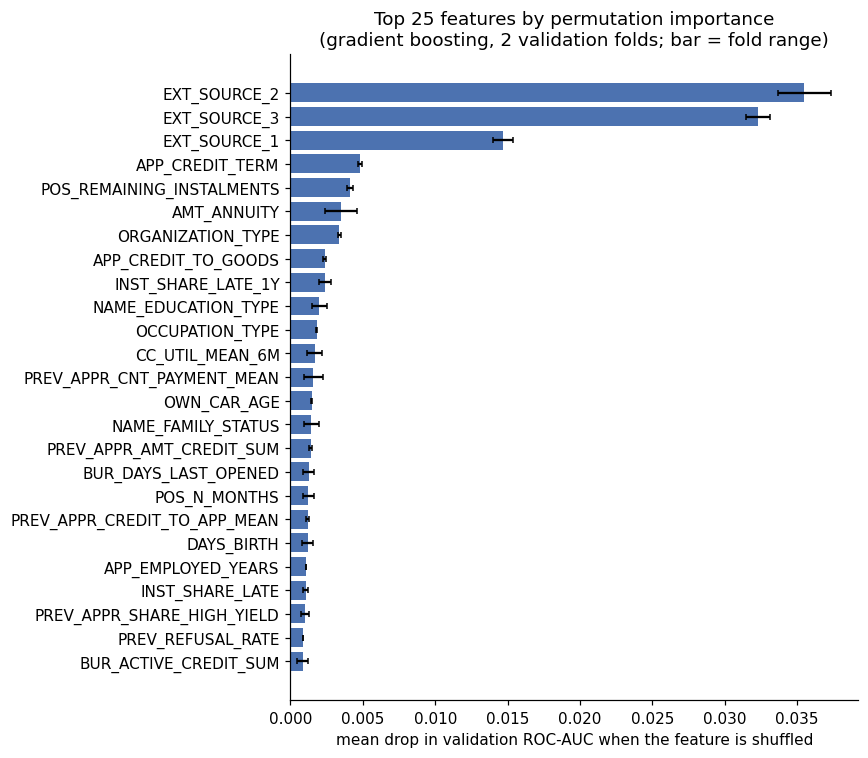

In [7]:
top = imp.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top["mean"], xerr=(top[["fold_0", "fold_1"]].max(axis=1) - top[["fold_0", "fold_1"]].min(axis=1)) / 2,
        color="#4C72B0", capsize=2)
ax.set(title="Top 25 features by permutation importance\n(gradient boosting, 2 validation folds; bar = fold range)",
       xlabel="mean drop in validation ROC-AUC when the feature is shuffled")
plt.tight_layout(); fig.savefig(FIG / "07_permutation_importance.png", bbox_inches="tight"); plt.show()

In [8]:
REDUCED = CURRENT - set(dead)
cols_red = restrict(cols_all, REDUCED)
run(f"LR | {CURRENT_LABEL} - zero-importance", lambda: make_lr(cols_red))
run(f"HGB | {CURRENT_LABEL} - zero-importance", lambda: make_hgb(cols_red))
r = results()
lab_lr, lab_hgb = f"LR | {CURRENT_LABEL}", f"HGB | {CURRENT_LABEL}"
s = pd.concat([paired_summary(r, lab_lr, [lab_lr, f"{lab_lr} - zero-importance"]),
               paired_summary(r, lab_hgb, [lab_hgb, f"{lab_hgb} - zero-importance"])])
display(s[["roc_auc", "roc_auc_std", "pr_auc", "auc_diff_vs_ref", "folds_better_than_ref"]].round(4))
drop_dead = bool((s.loc[[f"{lab_lr} - zero-importance", f"{lab_hgb} - zero-importance"], "auc_diff_vs_ref"] >= -0.0005).all())
print("Decision rule:", f"REMOVE {len(dead)} zero-importance features" if drop_dead else "KEEP all features")
FINAL = REDUCED if drop_dead else CURRENT
FINAL_LABEL = f"{CURRENT_LABEL} - zero-importance" if drop_dead else CURRENT_LABEL
cols_final = restrict(cols_all, FINAL)
pd.Series(sorted(FINAL), name="feature").to_csv(REPORTS / "step7_final_features.csv", index=False)
print(f"FINAL feature set: {len(FINAL)} features ({FINAL_LABEL}) -> reports/step7_final_features.csv")
if drop_dead:
    print("Removed:", dead)

LR | ALL - EXT summaries - zero-importance ROC-AUC 0.7767 over 5 folds  (cached)


HGB | ALL - EXT summaries - zero-importance ROC-AUC 0.7804 over 5 folds  (cached)


,roc_auc,roc_auc_std,pr_auc,auc_diff_vs_ref,folds_better_than_ref
label,,,,,
LR | ALL - EXT summaries,0.7777,0.0028,0.2646,0.0000,0
LR | ALL - EXT summaries - zero-importance,0.7767,0.0025,0.2629,-0.0010,0
HGB | ALL - EXT summaries,0.7800,0.0030,0.2666,0.0000,0
HGB | ALL - EXT summaries - zero-importance,0.7804,0.0021,0.2682,0.0004,3


Decision rule: KEEP all features
FINAL feature set: 177 features (ALL - EXT summaries) -> reports/step7_final_features.csv


**Result.** 55 of the 177 features show no permutation importance in either fold. Removing them changes gradient boosting by
+0.0004 but costs Logistic Regression 0.0010 (worse in all 5 folds), which fails the decision rule. **All 177 features are
kept.** Features the trees ignore still carry information for the linear model.

The importance ranking itself is informative:
* the three external scores dominate (each costs 0.015–0.036 ROC-AUC when shuffled);
* they are followed by implied term, remaining POS instalments, annuity, organisation type, credit-to-goods ratio and the
  recent share of late instalments.

So engineered and recent-behaviour features rank among the most useful inputs.

### 15.3 Class imbalance: does reweighting or resampling help?
About 8% of loans are positives. Three approaches are compared, with the same models, features and folds:
* **None.** Unweighted training; the imbalance is handled later by choosing the decision threshold (Step 10).
* **Class weighting** (`class_weight="balanced"`). Positives are weighted about 11×.
* **Random undersampling** of negatives to a 1:1 ratio, **in the training part of each fold only**. Validation folds are never resampled.

**SMOTE is not tested.** It interpolates between neighbouring positive applicants, which is ill-defined for this data: 15 categorical
variables, one-hot columns, missing-value indicators and features where "missing" is information (Steps 3–5). It would also
roughly double the training matrix on a 4 GB machine.

**Decision rule.** An approach is adopted only if it raises ROC-AUC or PR-AUC by more than 0.001 in at least 4 of 5 folds. Both
weighting and undersampling deliberately distort predicted probabilities, so Brier score and log loss are reported too.

In [9]:
lab_lr0, lab_hgb0 = f"LR | {FINAL_LABEL}", f"HGB | {FINAL_LABEL}"   # unweighted references on the FINAL set
if lab_lr0 not in OOF:
    run(lab_lr0, lambda: make_lr(cols_final))
if lab_hgb0 not in OOF:
    run(lab_hgb0, lambda: make_hgb(cols_final))
run("LR | FINAL | balanced weights", lambda: make_lr(cols_final, class_weight="balanced"))
run("LR | FINAL | undersample 1:1", lambda: make_lr(cols_final), undersample_ratio=1.0)
run("HGB | FINAL | balanced weights", lambda: make_hgb(cols_final, class_weight="balanced"))
run("HGB | FINAL | undersample 1:1", lambda: make_hgb(cols_final), undersample_ratio=1.0)

r = results()
imb = []
for model, ref in [("LR", lab_lr0), ("HGB", lab_hgb0)]:
    labs = [ref, f"{model} | FINAL | balanced weights", f"{model} | FINAL | undersample 1:1"]
    s = paired_summary(r, ref, labs)
    base_pr = r[r.label == ref].set_index("fold").pr_auc
    s["pr_auc_diff_vs_ref"] = [(r[r.label == l].set_index("fold").pr_auc - base_pr).mean() for l in labs]
    s["folds_pr_better_0.001"] = [int(((r[r.label == l].set_index("fold").pr_auc - base_pr) > .001).sum()) for l in labs]
    s["folds_auc_better_0.001"] = [int(((r[r.label == l].set_index("fold").roc_auc
                                        - r[r.label == ref].set_index("fold").roc_auc) > .001).sum()) for l in labs]
    s["mean_predicted_pct"] = [100 * np.nanmean(OOF[l]) for l in labs]
    imb.append(s)
imb = pd.concat(imb)
imb.to_csv(REPORTS / "step7_imbalance_cv.csv")
display(imb[["roc_auc", "pr_auc", "auc_diff_vs_ref", "pr_auc_diff_vs_ref", "folds_auc_better_0.001",
             "folds_pr_better_0.001", "brier", "log_loss", "mean_predicted_pct", "fit_seconds"]].round(4))
print(f"Observed TARGET rate: {100 * y_dev.mean():.2f}%")
ADOPT = {}
for model in ["LR", "HGB"]:
    ok = imb[imb.index.str.startswith(model + " | FINAL | ")
             & ((imb["folds_auc_better_0.001"] >= 4) | (imb["folds_pr_better_0.001"] >= 4))]
    ADOPT[model] = None if ok.empty else ("balanced" if "balanced" in ok.roc_auc.idxmax() else "undersample")
CW = {m: ("balanced" if a == "balanced" else None) for m, a in ADOPT.items()}     # class_weight per model
US = {m: (1.0 if a == "undersample" else None) for m, a in ADOPT.items()}         # undersampling ratio per model
print("Decision rule per model:", {m: (a or "none - imbalance handled by the decision threshold (Step 10)")
                                   for m, a in ADOPT.items()})

LR | FINAL | balanced weights              ROC-AUC 0.7778 over 5 folds  (cached)


LR | FINAL | undersample 1:1               ROC-AUC 0.7757 over 5 folds  (cached)


HGB | FINAL | balanced weights             ROC-AUC 0.7807 over 5 folds  (cached)


HGB | FINAL | undersample 1:1              ROC-AUC 0.7758 over 5 folds  (cached)


,roc_auc,pr_auc,auc_diff_vs_ref,pr_auc_diff_vs_ref,folds_auc_better_0.001,folds_pr_better_0.001,brier,log_loss,mean_predicted_pct,fit_seconds
label,,,,,,,,,,
LR | ALL - EXT summaries,0.7777,0.2646,0.0000,0.0000,0,0,0.0667,0.2405,8.0725,22.7472
LR | FINAL | balanced weights,0.7778,0.2619,0.0002,-0.0027,0,0,0.1907,0.5642,39.9630,33.0066
LR | FINAL | undersample 1:1,0.7757,0.2593,-0.0020,-0.0053,0,0,0.1931,0.5701,40.2244,3.3210
HGB | ALL - EXT summaries,0.7800,0.2666,0.0000,0.0000,0,0,0.0666,0.2399,8.0203,25.8652
HGB | FINAL | balanced weights,0.7807,0.2695,0.0007,0.0029,3,4,0.1746,0.5228,37.6891,26.4392
HGB | FINAL | undersample 1:1,0.7758,0.2611,-0.0042,-0.0055,0,0,0.1932,0.5692,40.5450,4.9663


Observed TARGET rate: 8.07%
Decision rule per model: {'LR': 'none - imbalance handled by the decision threshold (Step 10)', 'HGB': 'balanced'}


**Result.**
* **Logistic Regression: no adjustment.** Balanced weights change ROC-AUC by +0.0002 and PR-AUC by −0.0027; undersampling
  loses on both. Neither beats the reference by more than 0.001 in any fold.
* **Gradient boosting: balanced weights adopted.** PR-AUC improves by 0.0029, by more than 0.001 in 4 of 5 folds, and ROC-AUC
  by 0.0007. The rule is met, so the weights are used from here on.
* **Undersampling loses for both models** (ROC-AUC −0.0020 and −0.0042): discarding most negatives throws away information.
* **Reweighting distorts probabilities, as expected.** The weighted gradient-boosting model predicts 37.69% on average against
  an observed 8.07%, with Brier score 0.1746 versus 0.0666. Section 17.2 therefore tests recalibration.

## 16. Step 8 — Modelling and hyperparameter tuning

| | Logistic Regression | Gradient boosting (`HistGradientBoostingClassifier`) |
|---|---|---|
| **Why** | Interpretable statistical baseline, standard for scorecards; coefficients have a direction and size | Captures non-linear effects and interactions (Steps 3 and 5 found several) without manual binning |
| **Preprocessing** | Step 4 variant D: impute, missing indicators, winsorise, log, decile bins, scale, one-hot | Raw numbers with native missing handling; categories as native splits |
| **Tuned** | L2 strength `C` (grid of 5 values, all 5 folds) | 6 random combinations of learning rate, leaves, leaf size, L2, feature subsampling; early stopping on an inner 10% split |
| **Baseline** | C = 1 (Steps 4–5 reference) | Library defaults (Step 5 reference) |

The gradient-boosting search screens candidates on folds 0–2 to fit the compute budget. The winner is then run on folds 3–4,
so every final model has five-fold out-of-fold predictions. **Tuning is only claimed to help if the measured
fold-by-fold results show it.**

In [10]:
C_GRID = [0.003, 0.01, 0.03, 0.1, 1.0] if not QUICK else [0.01, 1.0]
lr_labels = []
for C in C_GRID:
    lab = f"LR | FINAL | C={C}"
    if C == 1.0 and ADOPT["LR"] is None:
        RESULTS.append(results().query("label == @lab_lr0").assign(label=lab))
        OOF[lab] = OOF[lab_lr0]
        print(f"{lab:42s} (same configuration as '{lab_lr0}', reused)")
    else:
        run(lab, lambda C=C: make_lr(cols_final, C=C, class_weight=CW["LR"]), undersample_ratio=US["LR"])
    lr_labels.append(lab)
lr_tab = paired_summary(results(), f"LR | FINAL | C=1.0", lr_labels)
display(lr_tab[["roc_auc", "roc_auc_std", "pr_auc", "brier", "auc_diff_vs_ref", "folds_better_than_ref",
                "fit_seconds"]].round(4))
BEST_C = float(lr_tab.roc_auc.idxmax().split("C=")[1])
LR_FINAL = f"LR | FINAL | C={BEST_C}"
print(f"Selected C = {BEST_C} (highest mean ROC-AUC)")

LR | FINAL | C=0.003                       ROC-AUC 0.7773 over 5 folds  (cached)


LR | FINAL | C=0.01                        ROC-AUC 0.7778 over 5 folds  (cached)


LR | FINAL | C=0.03                        ROC-AUC 0.7778 over 5 folds  (cached)


LR | FINAL | C=0.1                         ROC-AUC 0.7777 over 5 folds  (cached)


LR | FINAL | C=1.0                         (same configuration as 'LR | ALL - EXT summaries', reused)


,roc_auc,roc_auc_std,pr_auc,brier,auc_diff_vs_ref,folds_better_than_ref,fit_seconds
label,,,,,,,
LR | FINAL | C=0.003,0.7773,0.0027,0.2639,0.0667,-0.0004,1,18.4207
LR | FINAL | C=0.01,0.7778,0.0027,0.2645,0.0667,0.0001,3,16.8442
LR | FINAL | C=0.03,0.7778,0.0027,0.2647,0.0667,0.0001,4,17.6536
LR | FINAL | C=0.1,0.7777,0.0027,0.2646,0.0667,0.0000,4,19.2236
LR | FINAL | C=1.0,0.7777,0.0028,0.2646,0.0667,0.0000,0,22.7472


Selected C = 0.01 (highest mean ROC-AUC)


In [11]:
space = {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [50, 200, 500],
         "l2_regularization": [0.0, 1.0, 10.0], "max_features": [0.5, 0.8, 1.0]}
fixed = dict(max_iter=150 if QUICK else 600, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30)
cands = list(ParameterSampler(space, n_iter=2 if QUICK else 6, random_state=SEED))
screen_folds = [0, 1, 2]
search = []
for i, params in enumerate(cands):
    lab = f"HGB | FINAL | cand {i}"
    res = run(lab, lambda params=params: make_hgb(cols_final, class_weight=CW["HGB"], **params, **fixed),
              fold_ids=screen_folds, undersample_ratio=US["HGB"])
    search.append({**params, "label": lab, "roc_auc_folds_0_2": res.roc_auc.mean(), "pr_auc": res.pr_auc.mean(),
                   "mean_iterations": res.n_iter.mean(), "fit_seconds": res.fit_seconds.mean()})
search = pd.DataFrame(search).sort_values("roc_auc_folds_0_2", ascending=False)
search.to_csv(REPORTS / "step8_hgb_search.csv", index=False)
default_02 = results().query("label == @lab_hgb0 and fold in @screen_folds").roc_auc.mean()
print(f"Default gradient boosting on the same folds 0-2: ROC-AUC {default_02:.4f}")
display(search.round(4))

HGB | FINAL | cand 0                       ROC-AUC 0.7816 over 3 folds  (cached)


HGB | FINAL | cand 1                       ROC-AUC 0.7836 over 3 folds  (cached)


HGB | FINAL | cand 2                       ROC-AUC 0.7825 over 3 folds  (cached)


HGB | FINAL | cand 3                       ROC-AUC 0.7823 over 3 folds  (cached)


HGB | FINAL | cand 4                       ROC-AUC 0.7802 over 3 folds  (cached)


HGB | FINAL | cand 5                       ROC-AUC 0.7815 over 3 folds  (cached)


Default gradient boosting on the same folds 0-2: ROC-AUC 0.7791


,min_samples_leaf,max_leaf_nodes,max_features,learning_rate,l2_regularization,label,roc_auc_folds_0_2,pr_auc,mean_iterations,fit_seconds
1,200,15,0.5,0.05,10.0,HGB | FINAL | cand 1,0.7836,0.2737,465.6667,75.6041
2,500,31,1.0,0.05,10.0,HGB | FINAL | cand 2,0.7825,0.2724,267.0000,62.9586
3,200,15,0.5,0.05,1.0,HGB | FINAL | cand 3,0.7823,0.2720,348.3333,59.6777
0,500,31,1.0,0.10,10.0,HGB | FINAL | cand 0,0.7816,0.2699,138.6667,35.0795
5,500,15,0.5,0.10,0.0,HGB | FINAL | cand 5,0.7815,0.2709,217.0000,40.1367
4,200,31,0.8,0.10,1.0,HGB | FINAL | cand 4,0.7802,0.2704,134.0000,32.4484


In [12]:
best = search.iloc[0]
BEST_HGB = {k: (int(best[k]) if k in ("max_leaf_nodes", "min_samples_leaf") else float(best[k])) for k in space}
res_rest = run("HGB | FINAL | tuned (folds 3-4)", lambda: make_hgb(cols_final, class_weight=CW["HGB"], **BEST_HGB, **fixed),
              fold_ids=[3, 4], undersample_ratio=US["HGB"])
HGB_FINAL = "HGB | FINAL | tuned"
r = results()
tuned = pd.concat([r[(r.label == best.label)], r[r.label == "HGB | FINAL | tuned (folds 3-4)"]]).assign(label=HGB_FINAL)
RESULTS.append(tuned)
OOF[HGB_FINAL] = np.where(np.isnan(OOF[best.label]), OOF["HGB | FINAL | tuned (folds 3-4)"], OOF[best.label])
assert not np.isnan(OOF[HGB_FINAL]).any()
print("Selected gradient-boosting parameters:", BEST_HGB, "| fixed:", fixed)
cmp8 = paired_summary(results(), lab_hgb0, [lab_hgb0, HGB_FINAL])
display(cmp8[["roc_auc", "roc_auc_std", "pr_auc", "brier", "auc_diff_vs_ref", "folds_better_than_ref", "fit_seconds"]].round(4))
print(f"Mean boosting iterations used by the tuned model: {tuned.n_iter.mean():.0f} (cap {fixed['max_iter']})")

HGB | FINAL | tuned (folds 3-4)            ROC-AUC 0.7860 over 2 folds  (cached)


Selected gradient-boosting parameters: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'l2_regularization': 10.0, 'max_features': 0.5} | fixed: {'max_iter': 600, 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 30}


,roc_auc,roc_auc_std,pr_auc,brier,auc_diff_vs_ref,folds_better_than_ref,fit_seconds
label,,,,,,,
HGB | ALL - EXT summaries,0.7800,0.0030,0.2666,0.0666,0.0000,0,25.8652
HGB | FINAL | tuned,0.7846,0.0024,0.2745,0.1751,0.0045,5,74.0094


Mean boosting iterations used by the tuned model: 451 (cap 600)


**Result.**
* **Logistic Regression: tuning changes almost nothing.** C between 0.01 and 1 gives ROC-AUC 0.7777–0.7778. C = 0.01 is selected
  by the rule, but its gain over C = 1 (+0.0001) is negligible. The model is already well regularised by its preprocessing,
  and 246,008 rows leave little variance to control. **No real improvement from tuning is claimed.**
* **Gradient boosting: tuning helps.** The best candidate uses learning rate 0.05, 15 leaves, at least 200 samples per leaf,
  L2 = 10 and 50% feature subsampling, i.e. many small, strongly regularised trees (451 iterations on average). Across all
  5 folds it reaches 0.7846 versus 0.7800 for the defaults (+0.0045, better in all 5 folds).

  This gain combines tuning *and* the balanced weights adopted in 15.3. The weights alone added 0.0007, so roughly 0.004 is
  attributable to the hyperparameters. The search covered only 6 candidates, so a larger search could find more.
* **The cost is speed.** The tuned model fits in about 74 s versus 26 s for the defaults, and scores at 0.08 s per 1,000
  applicants. That is fast enough for real-time decisions.

## 17. Step 9 — Model evaluation and selection

### 17.1 Comparison on out-of-fold predictions
Every loan in the development data receives a prediction from a model that never saw it in training. The metrics below
are averaged over folds. The **threshold-dependent** columns use the F1-maximising threshold on the out-of-fold
predictions. That threshold is a *statistical reference only*; the lending threshold is a business decision (Step 10).

In [13]:
compare = {"Logistic Regression (C=1, baseline)": f"LR | FINAL | C=1.0",
           f"Logistic Regression (tuned, C={BEST_C})": LR_FINAL,
           "Gradient boosting (defaults, baseline)": lab_hgb0,
           "Gradient boosting (tuned)": HGB_FINAL}
r = results()
n_inputs = {"LR": len(make_lr(cols_final)[0].fit(X_dev).get_feature_names_out()),
            "HGB": len(cols_final["continuous"]) + len(cols_final["binary"]) + len(cols_final["categorical"])}
rows = []
for name, lab in compare.items():
    g = r[r.label == lab]
    p = OOF[lab]
    thr = f1_optimal_threshold(y_dev, p)
    tm = threshold_metrics(y_dev, p, thr)
    rows.append({"model": name, "roc_auc": g.roc_auc.mean(), "roc_auc_std": g.roc_auc.std(), "gini": g.gini.mean(),
                 "pr_auc": g.pr_auc.mean(), "ks": g.ks.mean(), "brier": g.brier.mean(), "log_loss": g.log_loss.mean(),
                 "ece": expected_calibration_error(y_dev, p), "f1_threshold": thr, "flagged_pct": tm["flagged_pct"],
                 "precision": tm["precision"], "recall": tm["recall"], "f1": tm["f1"],
                 "fit_seconds": g.fit_seconds.mean(), "predict_seconds_per_1k": g.predict_seconds_per_1k.mean(),
                 "model_inputs": n_inputs["LR" if lab.startswith("LR") else "HGB"]})
model_cmp = pd.DataFrame(rows).set_index("model")
model_cmp.to_csv(REPORTS / "model_results.csv")
display(model_cmp.round(4))
d = (r[r.label == HGB_FINAL].set_index("fold").roc_auc - r[r.label == LR_FINAL].set_index("fold").roc_auc)
print(f"Tuned gradient boosting minus tuned Logistic Regression, ROC-AUC per fold: {d.round(4).to_dict()} "
      f"(mean {d.mean():.4f}, better in {(d > 0).sum()}/5 folds)")

,roc_auc,roc_auc_std,gini,pr_auc,ks,brier,log_loss,ece,f1_threshold,flagged_pct,precision,recall,f1,fit_seconds,predict_seconds_per_1k,model_inputs
model,,,,,,,,,,,,,,,,
"Logistic Regression (C=1, baseline)",0.7777,0.0028,0.5554,0.2646,0.4190,0.0667,0.2405,0.0024,0.1562,13.7496,0.2607,0.4441,0.3285,22.7472,0.0132,403
"Logistic Regression (tuned, C=0.01)",0.7778,0.0027,0.5556,0.2645,0.4194,0.0667,0.2404,0.0023,0.1591,13.2097,0.2649,0.4335,0.3289,16.8442,0.0160,403
"Gradient boosting (defaults, baseline)",0.7800,0.0030,0.5600,0.2666,0.4249,0.0666,0.2399,0.0050,0.1544,13.3386,0.2646,0.4372,0.3297,25.8652,0.0266,177
Gradient boosting (tuned),0.7846,0.0024,0.5691,0.2745,0.4328,0.1751,0.5245,0.2972,0.6646,13.4268,0.2667,0.4436,0.3331,74.0094,0.0822,177


Tuned gradient boosting minus tuned Logistic Regression, ROC-AUC per fold: {0: 0.0075, 1: 0.0072, 2: 0.0073, 3: 0.0072, 4: 0.0046} (mean 0.0068, better in 5/5 folds)


**Result.**
* **Ranking.** Tuned gradient boosting has the highest ROC-AUC (0.7846, Gini 0.5691), PR-AUC (0.2745) and KS (0.4328). Its lead over
  tuned Logistic Regression (0.7778) is 0.0068 on average and holds in all 5 folds, from 0.0046 to 0.0075.
* **Probabilities.** Because of its balanced weights, its raw Brier score (0.1751) and ECE (0.2972) are poor. Section 17.2 addresses this.
* **At the F1-maximising reference threshold** both models flag about 13% of applicants and catch about 44% of the
  payment-difficulty cases, with precision of about 0.27. Roughly 1 in 4 flagged applicants actually has difficulties.
  This is typical of credit scoring with an 8% base rate. It is also why the threshold must come from costs (Step 10),
  not from F1.

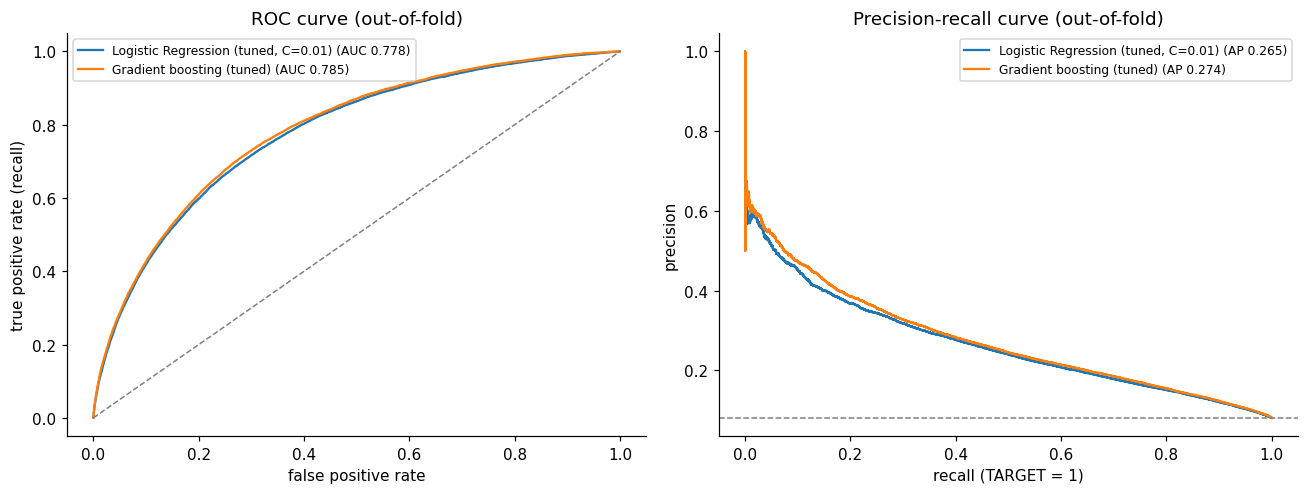

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for name in [f"Logistic Regression (tuned, C={BEST_C})", "Gradient boosting (tuned)"]:
    p = OOF[compare[name]]
    fpr, tpr, _ = roc_curve(y_dev, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {model_cmp.loc[name, 'roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(y_dev, p)
    ax[1].plot(rc, pr, label=f"{name} (AP {model_cmp.loc[name, 'pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
ax[0].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve (out-of-fold)")
ax[1].axhline(y_dev.mean(), ls="--", c="grey", lw=1)
ax[1].set(xlabel="recall (TARGET = 1)", ylabel="precision", title="Precision-recall curve (out-of-fold)")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "09_roc_pr_oof.png", bbox_inches="tight"); plt.show()

### 17.2 Calibration: can the probabilities be used as probabilities?
Step 10 turns probabilities into expected losses, so a predicted 10% should mean about 10% of such applicants have payment
difficulties.

**Method.**
* Reliability tables compare predicted and observed rates by decile.
* The expected calibration error (ECE) summarises the gap.
* **Cross-validated isotonic recalibration** is tested: each fold's calibrator is fitted on the other folds' out-of-fold
  predictions only, so the calibrated values stay out-of-sample.

**Decision rule.** Recalibrate only if it lowers the Brier score *and* the ECE.

brier  log_loss      ece  roc_auc_pooled  mean_predicted_pct
model                               probabilities                                                                             
Logistic Regression (tuned, C=0.01) raw                         0.06667   0.24045  0.00226         0.77777             8.08013
                                    isotonic (cross-validated)  0.06667   0.24058  0.00077         0.77701             8.07240
Gradient boosting (tuned)           raw                         0.17511   0.52446  0.29724         0.78453            37.79695
                                    isotonic (cross-validated)  0.06619   0.23837  0.00049         0.78383             8.07298

Observed TARGET rate: 8.073%


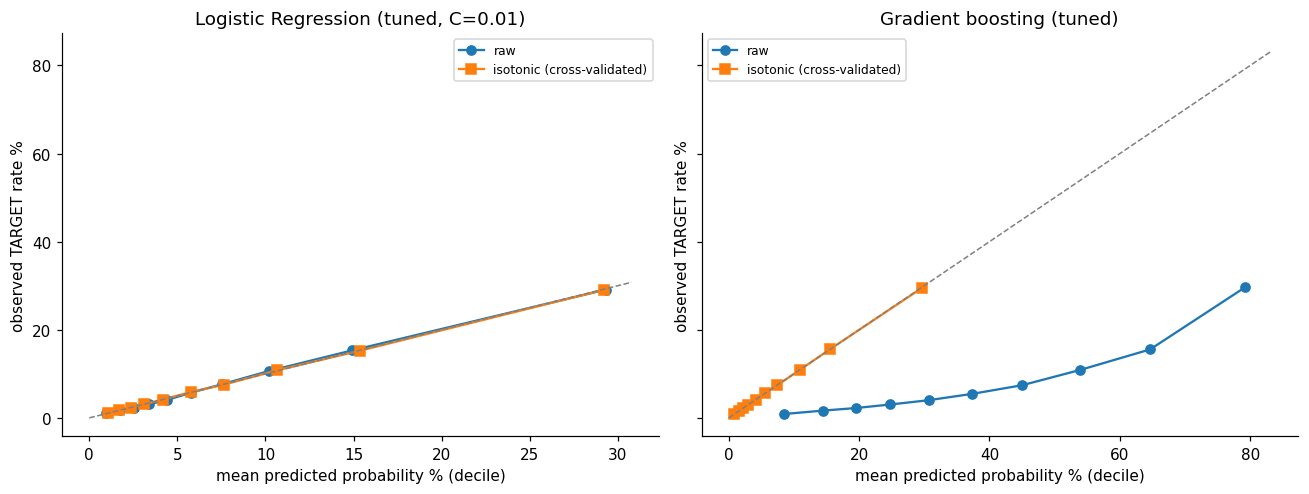

,n,mean_predicted,observed_rate,gap
bin,,,,
0,24601,8.44,0.87,-7.57
1,24601,14.42,1.65,-12.78
2,24601,19.52,2.24,-17.28
3,24600,24.82,3.04,-21.78
4,24601,30.65,4.01,-26.65
5,24601,37.30,5.44,-31.86
6,24600,45.02,7.41,-37.61
7,24601,53.94,10.89,-43.05
8,24601,64.64,15.54,-49.10


In [15]:
fold_dev = dev.fold.to_numpy()
cal_rows, curves = [], {}
for name in [f"Logistic Regression (tuned, C={BEST_C})", "Gradient boosting (tuned)"]:
    p = OOF[compare[name]]
    pc = cv_isotonic(p, y_dev, fold_dev)
    for kind, q in [("raw", p), ("isotonic (cross-validated)", pc)]:
        m = ranking_metrics(y_dev, q)
        cal_rows.append({"model": name, "probabilities": kind, "brier": m["brier"], "log_loss": m["log_loss"],
                         "ece": expected_calibration_error(y_dev, q), "roc_auc_pooled": m["roc_auc"],
                         "mean_predicted_pct": 100 * q.mean()})
        curves[(name, kind)] = calibration_table(y_dev, q)
cal = pd.DataFrame(cal_rows).set_index(["model", "probabilities"])
display(cal.round(5))
print(f"Observed TARGET rate: {100 * y_dev.mean():.3f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for a, name in zip(ax, [f"Logistic Regression (tuned, C={BEST_C})", "Gradient boosting (tuned)"]):
    for kind, mk in [("raw", "o"), ("isotonic (cross-validated)", "s")]:
        t = curves[(name, kind)]
        a.plot(100 * t.mean_predicted, 100 * t.observed_rate, marker=mk, label=kind)
    lim = 100 * max(curves[(name, "raw")].observed_rate.max(), curves[(name, "raw")].mean_predicted.max()) * 1.05
    a.plot([0, lim], [0, lim], ls="--", c="grey", lw=1)
    a.set(title=name, xlabel="mean predicted probability % (decile)", ylabel="observed TARGET rate %")
    a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "09_calibration_oof.png", bbox_inches="tight"); plt.show()
display(curves[("Gradient boosting (tuned)", "raw")].assign(
    mean_predicted=lambda t: (100 * t.mean_predicted).round(2), observed_rate=lambda t: (100 * t.observed_rate).round(2),
    gap=lambda t: (100 * t.gap).round(2)))

**Result.**
* **Logistic Regression** is already well calibrated: ECE 0.0023, mean prediction 8.08% versus 8.07% observed. Isotonic
  recalibration lowers ECE but not the Brier score (0.06667 both), so by the rule it is **not** applied.
* **Gradient boosting with balanced weights** over-predicts in every decile. Its top decile averages 79.21% predicted versus
  29.65% observed. Cross-validated isotonic recalibration fixes this almost completely: Brier 0.1751 → 0.0662, ECE
  0.2972 → 0.0005, mean prediction 8.07%. Ranking is essentially unchanged (pooled ROC-AUC 0.7845 → 0.7838; isotonic steps
  create small ties). **Recalibration is applied** to the gradient-boosting model.

So both models can supply probabilities for expected-loss calculations in Step 10.

### 17.3 Error analysis at the reference threshold
At the F1-maximising threshold, the confusion matrix shows how the two error types trade off:
* **False negatives** are applicants with payment difficulties who would be *approved*. They cost credit losses.
* **False positives** are applicants who would repay but are *flagged*. They cost lost business and financial inclusion.

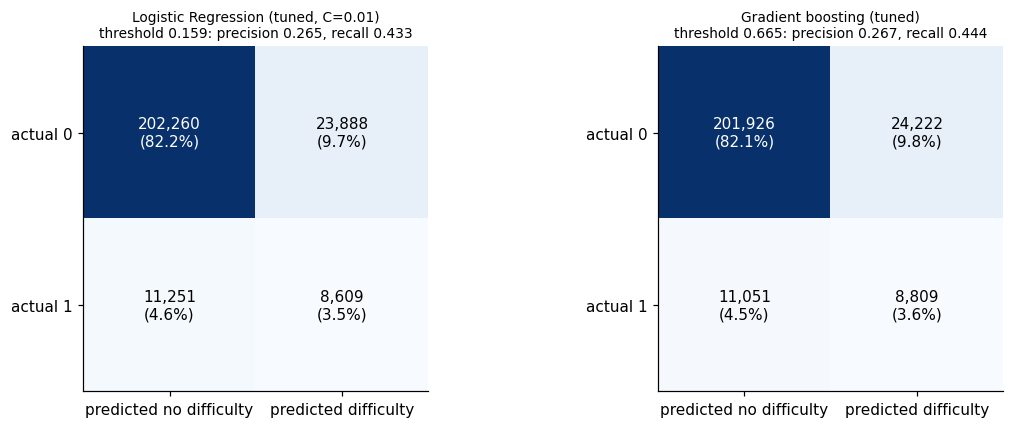

Performance by product (out-of-fold):


loans  target_pct  roc_auc  pr_auc  mean_predicted_pct
model                               contract_type                                                           
Logistic Regression (tuned, C=0.01) Cash loans       222560      8.3447   0.7771  0.2695              8.3425
                                    Revolving loans   23448      5.4930   0.7700  0.1783              5.5899
Gradient boosting (tuned)           Cash loans       222560      8.3447   0.7837  0.2797             38.5414
                                    Revolving loans   23448      5.4930   0.7793  0.1851             30.7308

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, name in zip(ax, [f"Logistic Regression (tuned, C={BEST_C})", "Gradient boosting (tuned)"]):
    tm = threshold_metrics(y_dev, OOF[compare[name]], model_cmp.loc[name, "f1_threshold"])
    cm = np.array([[tm["tn"], tm["fp"]], [tm["fn"], tm["tp"]]])
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, f"{v:,}\n({100 * v / cm.sum():.1f}%)", ha="center", va="center",
               color="white" if v > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["predicted no difficulty", "predicted difficulty"])
    a.set_yticks([0, 1], ["actual 0", "actual 1"])
    a.set_title(f"{name}\nthreshold {tm['threshold']:.3f}: precision {tm['precision']:.3f}, recall {tm['recall']:.3f}",
                fontsize=9)
plt.tight_layout(); fig.savefig(FIG / "09_confusion_oof.png", bbox_inches="tight"); plt.show()

seg = []
for name in [f"Logistic Regression (tuned, C={BEST_C})", "Gradient boosting (tuned)"]:
    for ct, m in dev.groupby("NAME_CONTRACT_TYPE").groups.items():
        idx = dev.index.get_indexer(m)
        rm = ranking_metrics(y_dev[idx], OOF[compare[name]][idx])
        seg.append({"model": name, "contract_type": ct, "loans": len(idx), "target_pct": 100 * y_dev[idx].mean(),
                    "roc_auc": rm["roc_auc"], "pr_auc": rm["pr_auc"], "mean_predicted_pct": 100 * OOF[compare[name]][idx].mean()})
print("Performance by product (out-of-fold):")
display(pd.DataFrame(seg).set_index(["model", "contract_type"]).round(4))

**Result.** At the reference threshold, most errors are false positives (good applicants flagged). Because positives are rare,
even a precise model has to flag several good applicants for each risky one it catches. The trade-off between the two
error types is priced in Step 10.

By product, both models rank cash loans better than revolving loans (gradient boosting 0.7837 versus 0.7793 out-of-fold).
Revolving loans are about 9.5% of development data but only 0.9% of the scoring set (notebook 01, Section 7), so the cash-loan performance is the more relevant
figure for deployment.

### 17.4 Robustness: how much do the models depend on unstable or external inputs?
Three questions from earlier steps are answered on folds 0–2 for both tuned models, each compared against the tuned model on the same folds:
* **+ drift-risk features.** Do the excluded monthly-bureau and bureau-annuity features (Step 4/5 drift) add enough to justify
  their risk?
* **− unstable features.** What is lost without `APP_CREDIT_TERM` and `APP_N_DOCUMENTS`, the two included features with a major
  PSI shift (Step 5)?
* **− all external scores.** How dependent is the scorecard on the three external scores of undocumented origin (Step 3)?

In [17]:
cols_drift_all = decide_columns(dev, include_drift=True)
cols_drift = restrict(cols_drift_all, FINAL | set(DRIFT_RISK))
UNSTABLE = {"APP_CREDIT_TERM", "APP_N_DOCUMENTS"}
EXT_ALL = {"EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "APP_EXT_MEAN", "APP_EXT_MIN", "APP_EXT_MAX", "APP_EXT_STD",
           "APP_EXT_N_MISSING"}
variants = {"+ drift-risk features": cols_drift, "- unstable features": restrict(cols_all, FINAL - UNSTABLE),
            "- all external scores": restrict(cols_all, FINAL - EXT_ALL)}
rob = []
for model, ref, maker in [("LR", LR_FINAL, lambda c: make_lr(c, C=BEST_C, class_weight=CW["LR"])),
                          ("HGB", HGB_FINAL, lambda c: make_hgb(c, class_weight=CW["HGB"], **BEST_HGB, **fixed))]:
    labs = [ref]
    for vname, c in variants.items():
        lab = f"{model} | tuned {vname}"
        run(lab, lambda c=c, maker=maker: maker(c), fold_ids=[0, 1, 2], undersample_ratio=US[model])
        labs.append(lab)
    rob.append(paired_summary(results(), ref, labs))
rob = pd.concat(rob)
rob.to_csv(REPORTS / "step9_robustness_cv.csv")
display(rob[["folds", "roc_auc", "pr_auc", "auc_diff_vs_ref", "folds_better_than_ref", "common_folds"]].round(4))

LR | tuned + drift-risk features           ROC-AUC 0.7763 over 3 folds  (cached)


LR | tuned - unstable features             ROC-AUC 0.7749 over 3 folds  (cached)


LR | tuned - all external scores           ROC-AUC 0.7494 over 3 folds  (cached)


HGB | tuned + drift-risk features          ROC-AUC 0.7831 over 3 folds  ( 226s)


HGB | tuned - unstable features            ROC-AUC 0.7816 over 3 folds  ( 223s)


HGB | tuned - all external scores          ROC-AUC 0.7577 over 3 folds  ( 212s)


,folds,roc_auc,pr_auc,auc_diff_vs_ref,folds_better_than_ref,common_folds
label,,,,,,
LR | FINAL | C=0.01,5,0.7778,0.2645,0.0000,0,5
LR | tuned + drift-risk features,3,0.7763,0.2639,0.0001,3,3
LR | tuned - unstable features,3,0.7749,0.2611,-0.0013,0,3
LR | tuned - all external scores,3,0.7494,0.2316,-0.0269,0,3
HGB | FINAL | tuned,5,0.7846,0.2745,0.0000,0,5
HGB | tuned + drift-risk features,3,0.7831,0.2746,-0.0005,0,3
HGB | tuned - unstable features,3,0.7816,0.2715,-0.0020,0,3
HGB | tuned - all external scores,3,0.7577,0.2394,-0.0259,0,3


**Result.**
* **Drift-risk features: stay excluded.** Adding them changes ROC-AUC by −0.0005 (gradient boosting) and +0.0001 (Logistic
  Regression). They add nothing measurable, while their coverage differs drastically in the scoring data.
* **Unstable features: kept.** Removing `APP_CREDIT_TERM` and `APP_N_DOCUMENTS` costs 0.0020 and 0.0013. The loss is modest,
  so the model does not hinge on them, but they help. They go on the monitoring list. A no-unstable-features variant is a
  ready fallback if their distribution keeps shifting.
* **External scores: a critical dependency.** Without them ROC-AUC falls by 0.0259 (gradient boosting) and 0.0269 (Logistic
  Regression), to about 0.75–0.76. Removing them would cost more than all five history tables add together (Step 5:
  +0.0216). Their availability, provenance and stability must be part of model governance (Step 11).

### 17.5 Model selection
**Decision rule, set before the holdout is opened.** Gradient boosting is selected only if its ROC-AUC exceeds tuned Logistic
Regression's by **at least 0.005 on average and in at least 4 of 5 folds**. Otherwise Logistic Regression is selected for its
transparency (reason codes from coefficients, simpler validation and monitoring).

Calibration (17.2), robustness (17.4) and operational cost are then reviewed for the selected model, and the other model is
kept as the **challenger**.

In [18]:
d = (r[r.label == HGB_FINAL].set_index("fold").roc_auc - r[r.label == LR_FINAL].set_index("fold").roc_auc)
SELECTED = "HGB" if (d.mean() >= 0.005 and (d > 0).sum() >= 4) else "LR"
names = {"LR": f"Logistic Regression (tuned, C={BEST_C})", "HGB": "Gradient boosting (tuned)"}
CHALLENGER = "LR" if SELECTED == "HGB" else "HGB"
CALIBRATE = {}
for k in ["LR", "HGB"]:                       # 17.2 rule, applied to each model separately
    c = cal.loc[names[k]]
    CALIBRATE[k] = bool((c.loc["isotonic (cross-validated)", "brier"] < c.loc["raw", "brier"])
                        and (c.loc["isotonic (cross-validated)", "ece"] < c.loc["raw", "ece"]))
print(f"ROC-AUC advantage of gradient boosting: mean {d.mean():.4f}, better in {(d > 0).sum()}/5 folds")
print(f"SELECTED: {names[SELECTED]} | challenger: {names[CHALLENGER]} | isotonic recalibration: "
      f"{ {names[k]: v for k, v in CALIBRATE.items()} }")

ROC-AUC advantage of gradient boosting: mean 0.0068, better in 5/5 folds
SELECTED: Gradient boosting (tuned) | challenger: Logistic Regression (tuned, C=0.01) | isotonic recalibration: {'Logistic Regression (tuned, C=0.01)': False, 'Gradient boosting (tuned)': True}


**Decision.** Tuned gradient boosting beats tuned Logistic Regression by 0.0068 on average and in 5 of 5 folds, which passes the
rule (≥ 0.005 and ≥ 4 folds). **Gradient boosting is selected, with isotonic recalibration.** Logistic Regression is the
challenger:
* it remains the transparent benchmark;
* it serves as a fallback if the selected model's monitoring raises concerns;
* it is a source of easily communicated risk drivers in Step 11.

**What the selection trades.** An extra 0.0068 ROC-AUC, and better ranking on both products, comes at the cost of less direct
interpretability. Step 11 offsets this with SHAP explanations and checks them against the Logistic Regression coefficients.

### 17.6 Final evaluation on the locked holdout (used once)
Both tuned models are refitted on all development folds and scored **once** on the 20% holdout. Where the 17.2 decision rule
adopted recalibration for a model, its isotonic calibrator is fitted on the development out-of-fold predictions only. Nothing is
tuned or chosen on these results.

In [19]:
abt = pd.read_parquet(PROCESSED / "abt_train.parquet")
if QUICK:
    abt = abt.groupby("fold", group_keys=False).sample(frac=0.15, random_state=SEED)
hold = abt[abt.fold == -1].reset_index(drop=True)
del abt
release_memory()
y_hold = hold.TARGET.to_numpy()

from src.modeling import undersample
X_hold = hold.drop(columns=["TARGET", "fold"])
final = {}
for key, maker in [("LR", lambda: make_lr(cols_final, C=BEST_C, class_weight=CW["LR"])),
                   ("HGB", lambda: make_hgb(cols_final, class_weight=CW["HGB"], **BEST_HGB, **fixed))]:
    t = time.time()
    idx = undersample(np.arange(len(dev)), y_dev, US[key], SEED) if US[key] else np.arange(len(dev))
    final[key] = maker().fit(X_dev.iloc[idx], y_dev[idx])
    print(f"{names[key]} refitted on {len(dev):,} development rows in {time.time() - t:.0f}s", flush=True)
calibrators = {k: (IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(OOF[compare[names[k]]], y_dev)
                   if CALIBRATE[k] else None) for k in final}     # fitted on development out-of-fold predictions only

def predict(key, X):
    p = final[key].predict_proba(X)[:, 1]
    return calibrators[key].predict(p) if calibrators[key] is not None else p

hold_pred = {k: predict(k, X_hold) for k in final}
rows = []
for k, p in hold_pred.items():
    thr = model_cmp.loc[names[k], "f1_threshold"]
    if calibrators[k] is not None:
        thr = float(calibrators[k].predict([thr])[0])
    rows.append({"model": names[k] + (" [SELECTED]" if k == SELECTED else " [challenger]"), **ranking_metrics(y_hold, p),
                 "ece": expected_calibration_error(y_hold, p), **threshold_metrics(y_hold, p, thr)})
holdout_results = pd.DataFrame(rows).set_index("model")
holdout_results.to_csv(REPORTS / "holdout_results.csv")
print(f"Holdout: {len(hold):,} loans, TARGET rate {100 * y_hold.mean():.2f}%")
display(holdout_results.round(4))
cv_auc = {k: model_cmp.loc[names[k], "roc_auc"] for k in final}
print("ROC-AUC holdout vs cross-validation:", {names[k]: (round(holdout_results.iloc[i].roc_auc, 4), round(cv_auc[k], 4))
                                               for i, k in enumerate(final)})

Logistic Regression (tuned, C=0.01) refitted on 246,008 development rows in 22s


Gradient boosting (tuned) refitted on 246,008 development rows in 106s


Holdout: 61,503 loans, TARGET rate 8.07%


,roc_auc,gini,pr_auc,ks,brier,log_loss,ece,threshold,flagged_pct,tp,fp,tn,fn,precision,recall,f1
model,,,,,,,,,,,,,,,,
"Logistic Regression (tuned, C=0.01) [challenger]",0.7827,0.5654,0.2748,0.4332,0.0662,0.2385,0.0034,0.1591,13.1555,2199,5892,50646,2766,0.2718,0.4429,0.3369
Gradient boosting (tuned) [SELECTED],0.7879,0.5759,0.2818,0.4357,0.0656,0.2362,0.0028,0.1675,13.5912,2265,6094,50444,2700,0.2710,0.4562,0.3400


ROC-AUC holdout vs cross-validation: {'Logistic Regression (tuned, C=0.01)': (np.float64(0.7827), np.float64(0.7778)), 'Gradient boosting (tuned)': (np.float64(0.7879), np.float64(0.7846))}


Holdout performance by product:


loans  target_pct  roc_auc  mean_predicted_pct
model                               contract_type                                                  
Logistic Regression (tuned, C=0.01) Cash loans       55672      8.3507   0.7835              8.2963
                                    Revolving loans   5831      5.4193   0.7550              5.6007
Gradient boosting (tuned)           Cash loans       55672      8.3507   0.7883              8.4106
                                    Revolving loans   5831      5.4193   0.7664              5.4650

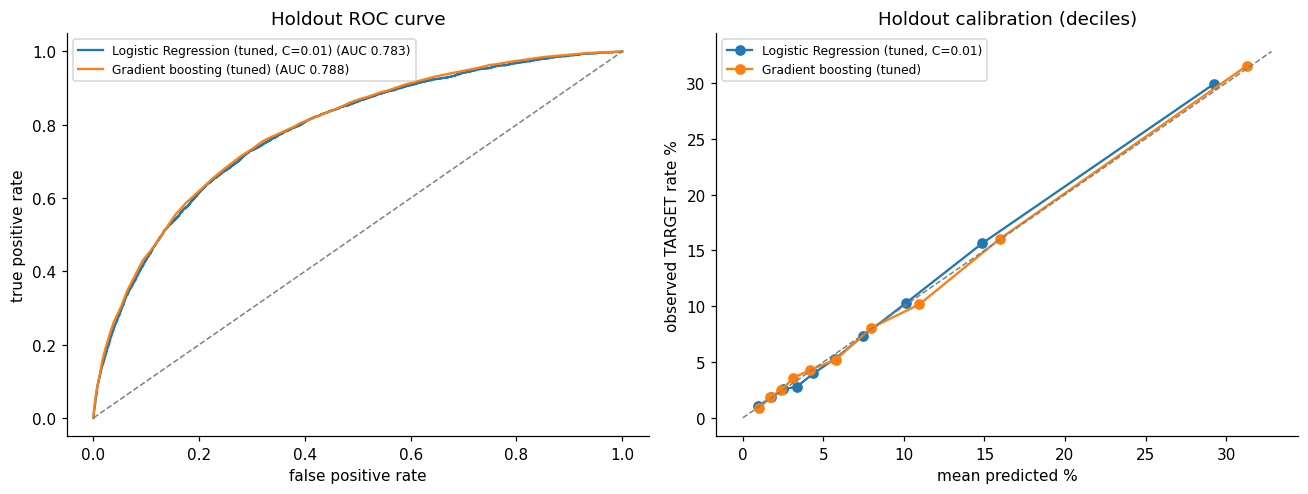

In [20]:
seg = []
for k, p in hold_pred.items():
    for ct, m in hold.groupby("NAME_CONTRACT_TYPE").groups.items():
        idx = hold.index.get_indexer(m)
        seg.append({"model": names[k], "contract_type": ct, "loans": len(idx), "target_pct": 100 * y_hold[idx].mean(),
                    "roc_auc": ranking_metrics(y_hold[idx], p[idx])["roc_auc"],
                    "mean_predicted_pct": 100 * p[idx].mean()})
print("Holdout performance by product:")
display(pd.DataFrame(seg).set_index(["model", "contract_type"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for k, p in hold_pred.items():
    fpr, tpr, _ = roc_curve(y_hold, p)
    ax[0].plot(fpr, tpr, label=f"{names[k]} (AUC {roc_auc_score(y_hold, p):.3f})")
    t = calibration_table(y_hold, p)
    ax[1].plot(100 * t.mean_predicted, 100 * t.observed_rate, marker="o", label=names[k])
ax[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
ax[0].set(title="Holdout ROC curve", xlabel="false positive rate", ylabel="true positive rate")
lim = ax[1].get_xlim()[1]
ax[1].plot([0, lim], [0, lim], ls="--", c="grey", lw=1)
ax[1].set(title="Holdout calibration (deciles)", xlabel="mean predicted %", ylabel="observed TARGET rate %")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "09_holdout_roc_calibration.png", bbox_inches="tight"); plt.show()

**Holdout result (opened once).**
* **Ranking:** the selected model reaches ROC-AUC 0.7879 (Gini 0.5759), PR-AUC 0.2818 and KS 0.4357; the challenger 0.7827. The ordering
  matches cross-validation.
* **Probabilities:** the recalibrated probabilities hold on new data, with ECE 0.0028 and Brier 0.0656.
* **Why the holdout scores are higher than cross-validation:** holdout ROC-AUC is slightly above the cross-validation figures
  (0.7846 and 0.7778). The final models are trained on all 246,008 development rows instead of four-fifths of them. A
  different random sample of 61,503 loans also varies by about the cross-validation fold spread (≈ 0.003). This is
  **not** evidence of leakage: the holdout was not loaded until this section.
* **At the reference threshold** the selected model flags 13.59% of holdout applicants and identifies 2,265 of the 4,965
  payment-difficulty cases (recall 0.4562, precision 0.2710). It misses 2,700, and 6,094 flagged applicants have no difficulty.
* **By product** it ranks cash loans at 0.7883 and revolving loans at 0.7664, with mean predictions close to the observed rates
  in both (8.41% versus 8.35%, 5.47% versus 5.42%).

Random splits overstate performance on future applicants (Step 6), so these are **upper-bound estimates** for production. A
controlled pilot (Step 11) is the right test before full deployment.

### 17.7 Saving the models and predictions for Steps 10–11
* **Models** go to `models/`. They are trained on personal data, so they are excluded from Git.
* **Predictions** go to `data/processed/`:
  * development out-of-fold predictions, used for threshold and cost analysis (Step 10);
  * holdout predictions, used to confirm the chosen policy once;
  * scoring-set predictions.

In [21]:
if not QUICK:
    for k, fname in [(SELECTED, "selected_model.joblib"), (CHALLENGER, "challenger_model.joblib")]:
        joblib.dump({"model": final[k], "calibrator": calibrators[k], "features": sorted(FINAL), "name": names[k]},
                    MODELS / fname)
    oof_out = {k: (cv_isotonic(OOF[compare[names[k]]], y_dev, fold_dev) if CALIBRATE[k] else OOF[compare[names[k]]])
               for k in ["LR", "HGB"]}
    oof_sel, oof_ch = oof_out[SELECTED], oof_out[CHALLENGER]
    pd.DataFrame({"SK_ID_CURR": dev.SK_ID_CURR, "fold": dev.fold, "TARGET": y_dev, "p_selected": oof_sel,
                  "p_challenger": oof_ch, "NAME_CONTRACT_TYPE": dev.NAME_CONTRACT_TYPE,
                  "AMT_CREDIT": dev.AMT_CREDIT, "AMT_ANNUITY": dev.AMT_ANNUITY}).to_parquet(PROCESSED / "pred_dev_oof.parquet", index=False)
    pd.DataFrame({"SK_ID_CURR": hold.SK_ID_CURR, "TARGET": y_hold, "p_selected": hold_pred[SELECTED],
                  "p_challenger": hold_pred[CHALLENGER], "NAME_CONTRACT_TYPE": hold.NAME_CONTRACT_TYPE,
                  "AMT_CREDIT": hold.AMT_CREDIT, "AMT_ANNUITY": hold.AMT_ANNUITY}).to_parquet(PROCESSED / "pred_holdout.parquet", index=False)
    score = pd.read_parquet(PROCESSED / "abt_test.parquet")
    pd.DataFrame({"SK_ID_CURR": score.SK_ID_CURR, "p_selected": predict(SELECTED, score),
                  "p_challenger": predict(CHALLENGER, score)}).to_csv(
        PROCESSED / "scoring_predictions.csv", index=False)
    print("Saved: models/selected_model.joblib, models/challenger_model.joblib, data/processed/pred_dev_oof.parquet,"
          " pred_holdout.parquet, scoring_predictions.csv")
    results().to_csv(REPORTS / "step7_9_all_cv_runs.csv", index=False)
else:
    print("QUICK mode: nothing saved")

Saved: models/selected_model.joblib, models/challenger_model.joblib, data/processed/pred_dev_oof.parquet, pred_holdout.parquet, scoring_predictions.csv


### 17.8 Steps 6–9 summary

| Decision | Evidence (development cross-validation unless stated) | Outcome |
|---|---|---|
| Validation design | Fixed in notebook 01; identical folds for every comparison; holdout used once | Unchanged |
| External-score summaries | −0.0003 (LR) / +0.0005 (gradient boosting) when removed | Removed |
| 55 zero-importance features | Removal costs LR 0.0010 | Kept (177 features) |
| Imbalance | LR: no gain from weighting or undersampling; gradient boosting: balanced weights +0.0029 PR-AUC (4/5 folds) | LR unweighted; gradient boosting balanced + recalibrated |
| SMOTE | Ill-defined for mixed categorical, one-hot and informative-missing data; memory cost | Not used (documented) |
| Tuning | LR: no material gain (C = 0.01); gradient boosting: +0.0045 incl. weights | Tuned settings used |
| Model selection | Gradient boosting +0.0068 ROC-AUC, 5/5 folds | **Gradient boosting (tuned, recalibrated)**; LR challenger |
| Holdout | ROC-AUC 0.7879, PR-AUC 0.2818, KS 0.4357, ECE 0.0028 | Confirms cross-validation |
| Dependencies | External scores: −0.0259 without them; unstable features: −0.0020; drift features: no gain | Governance and monitoring items for Step 11 |

**Saved for Steps 10–11:**
* `models/selected_model.joblib` and `models/challenger_model.joblib` (not in Git);
* out-of-fold development predictions and holdout predictions (`data/processed/pred_*.parquet`);
* scoring-set predictions for all 48,744 applications (`data/processed/scoring_predictions.csv`).

**Stage status.** Steps 6–9 are complete. Next is notebook 05: Step 10 (decision thresholds and business impact) and Step 11
(explainability, segments, fairness checks and recommendations).